In [1]:
%pip install scikit-learn
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import math
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## Below is the code for Harris Hawks implemented as close to the paper and pseudo code as possible. We think its real close with test verifying 

**Minor modifications with np.clip being used to keep hawks in bounds**

In [4]:
'''
    Harris Hawks Optimization (HHO) Algorithm Implementation

    Parameters:
        population_size : int
        -Number of hawks in the population

        dimensions : int
        -Number of dimensions of the problem

        lower_bound : float
        -Lower bound of the search space

        upper_bound : float
        -Upper bound of the search space

        T_iter : int
        -Number of iterations to run the algorithm
    '''
class HHO:
    def __init__(self, obj_func, population_size=30, dimensions=2, lower_bound=2, upper_bound=30, T_iter=100):


        self.chaos = False

        if self.chaos:
            with open("HHO_Chaos.py") as f:
                code = f.read()
            exec(code)

        self.obj_func = obj_func
        self.population_size = population_size
        self.dimensions = dimensions
        #self.lower_bound = lower_bound
        #self.upper_bound = upper_bound
        #orignally took in int values and scalar, bounds need to be able to take in arrays and also scalars of the same value for each dimension
        if isinstance(lower_bound, (int, float)):
            self.lower_bound = np.full(dimensions, lower_bound)
        else:
            self.lower_bound = np.array(lower_bound)

        if isinstance(upper_bound, (int, float)):
            self.upper_bound = np.full(dimensions, upper_bound)
        else:
            self.upper_bound = np.array(upper_bound)
        self.T_iter = T_iter
        self.hawks = self.initialize_hawks()
        self.initialize_rabbit()
        self.energy_curve = []
        self.best_curve = []
    '''
    Main loop of the HHO algorithm.
    The run method executes the HHO algorithm for T_iter iterations.
    It updates the positions of the hawks based on exploration and exploitation strategies.
    '''
    def run(self):
        for t in range(self.T_iter):
            for i in range(self.population_size):

                #Update the initial energy E0, jump strength J, and r(random number) each iteration
                E0 = 2 * np.random.rand() - 1
                J = 2 * (1 - np.random.rand())
                r = np.random.rand()

                #updat the energy level using equation(3) from the paper
                E = 2 * E0 * (1 - (t / self.T_iter))
                self.energy_curve.append(E)
                '''
                Start the exporation phase and the exploitation phase based on the energy level E
                1. Exploration phase |E| >= 1
                2. Exploitation phase |E| < 1
                '''
                #Set the current hawk and a random hawk from the population
                X_rand = self.hawks[np.random.randint(0, self.population_size)]
                X_curr = self.hawks[i]

                #Exploration phase
                if(abs(E) >= 1):

                    #random numbers used in the equations for updating location
                    r1 = np.random.rand()
                    r2 = np.random.rand()
                    r3 = np.random.rand()
                    r4 = np.random.rand()
                    q = np.random.rand()

                    #perching based on family members location
                    #Xrand(t) − r1 |Xrand(t) − 2r2X(t)|
                    if (q >= 0.5):
                        next_pos = X_rand - r1 * np.abs(X_rand - 2 * r2 * X_curr)

                    #perching around believed to be prey location
                    #(Xrabbit(t) − Xm(t)) − r3(LB + r4(UB − LB))
                    elif(q < 0.5):
                        Xm = np.mean(self.hawks, axis=0)
                        next_pos = (self.Xrabbit - Xm) - r3 * (self.lower_bound + r4 * (self.upper_bound - self.lower_bound))

                    #HHO produces hawks at positions outside of the bounds of the search space.
                    #Use numpy's clip function to ensure that the hawks stay within the bounds. (might work)
                    next_pos = np.clip(next_pos, self.lower_bound, self.upper_bound)

                    #update the position of hawk at i
                    self.hawks[i] = next_pos

                    #update the position of the rabbit if the new hawk position is better
                    fitness_i = self.obj_func(next_pos)
                    if fitness_i < self.fitness_rabbit:
                        self.Xrabbit = next_pos.copy()
                        self.fitness_rabbit = fitness_i

                #Exploitation phase
                if(abs(E) < 1):

                    #soft besiege
                    #X(t +1) = ∆X(t)−E|JXrabbit(t) − X(t)|
                    #∆X(t) = Xrabbit(t) − X(t)
                    if (r >=0.5 and abs(E)>= 0.5 ):
                        delta = self.Xrabbit - X_curr
                        next_pos = delta - E * np.abs(J * self.Xrabbit - X_curr)

                    #hard besiege
                    #X(t +1) = Xrabbit(t) − E |∆X(t)|
                    #delta same as soft besiege
                    elif (r >= 0.5 and abs(E) < 0.5 ):
                        delta = self.Xrabbit - X_curr
                        next_pos = self.Xrabbit - E * np.abs(delta)

                    #soft besiege with progressive rapid dives
                    #Y = Xrabbit(t) − E |JXrabbit(t) − X(t)|
                    #Z =Y + S×LF(D)
                    elif (r < 0.5 and abs(E) >= 0.5 ):
                        Y = self.Xrabbit - E * np.abs(J * self.Xrabbit - X_curr)
                        LF = self.levy_flight(self.dimensions)
                        Z = Y + np.random.rand(self.dimensions) * LF

                        #updated to ensure within bounds
                        Z = np.clip(Z, self.lower_bound, self.upper_bound)
                        Y = np.clip(Y, self.lower_bound, self.upper_bound)

                        #greedy selection based on the current hawk values
                        if self.obj_func(Z) < self.obj_func(X_curr):
                            next_pos = Z
                        elif self.obj_func(Y) < self.obj_func(X_curr):
                            next_pos = Y
                        else:
                            next_pos = X_curr

                    #hard besiege with progressive rapid dives
                    #Y = Xrabbit(t) − E |JXrabbit(t) − Xm(t)|
                    #Z = Y + S×LF(D)
                    elif (r < 0.5 and abs(E) < 0.5 ):
                        Y = self.Xrabbit - E * np.abs(J * self.Xrabbit - np.mean(self.hawks, axis=0))
                        LF = self.levy_flight(self.dimensions)
                        Z = Y + np.random.rand(self.dimensions) * LF

                        #updated to ensure within bounds
                        Z = np.clip(Z, self.lower_bound, self.upper_bound)
                        Y = np.clip(Y, self.lower_bound, self.upper_bound)

                        #greedy selection based on the current hawk values
                        if self.obj_func(Z) < self.obj_func(X_curr):
                            next_pos = Z
                        elif self.obj_func(Y) < self.obj_func(X_curr):
                            next_pos = Y
                        else:
                            next_pos = X_curr

                    #HHO produces hawks at positions outside of the bounds of the search space.
                    #Use numpy's clip function to ensure that the hawks stay within the bounds. (might work)
                    next_pos = np.clip(next_pos, self.lower_bound, self.upper_bound)

                    #update the position of hawk at i
                    self.hawks[i] = next_pos

                    #update the postion of the rabbit if the new hawk position is better
                    fitness_i = self.obj_func(next_pos)
                    if fitness_i < self.fitness_rabbit:
                        self.Xrabbit = next_pos.copy()
                        self.fitness_rabbit = fitness_i
                    self.best_curve.append(self.fitness_rabbit)

        #end of first for loop on pop size
        fitness = self.evaluate_population()
        idx = np.argmin(fitness)
        self.Xrabbit = self.hawks[idx].copy()
        self.fitness_rabbit = fitness[idx]

        return self.Xrabbit

    '''
    Evaluate the fitness of the hawks population

    The function below takes the obj function and evaluates
    all hawks in the population. It returns an array of fitness values corresponding to each hawk.
    1. Use a list comprehension to iterate over each hawk in self.hawks
    2. For each hawk, call self.obj_func(h) to get its fitness
    '''
    def evaluate_population(self):
        return np.array([self.obj_func(h) for h in self.hawks])


    '''
    Initialize the hawks population within the search space

    The below function generates a population of hawks with random postions
    within the defined lower and upper bounds.
    1. Use numpy's random.uniform function to generate random positions
    2. Use the lower_bound and upper_bound as the range for random values
    3. The shape of the generated array should be (population_size, dimensions)
    4. Return the initialized hawks population
    '''
    def initialize_hawks(self):
        return np.random.uniform(
            low=self.lower_bound,
            high=self.upper_bound,
            size=(self.population_size, self.dimensions)
        )

    '''
    Initialize the rabbit at the start of the algorithm.
    This function evaluates the initial population and sets the best hawk as the rabbit.
    Used at the beginning of the optimization process.

    1. Evaluate the fitness of the current population using self.evaluate_population()
    2. Find the index of the hawk with the best fitness (minimum value)
    3. Set self.Xrabbit to the position of the best hawk
    4. Set self.fitness_rabbit to the best fitness value
    '''
    def initialize_rabbit(self):
        fitness = self.evaluate_population()
        idx = np.argmin(fitness)
        self.Xrabbit = self.hawks[idx].copy()
        self.fitness_rabbit = fitness[idx]


    '''
    Levy Flight function to generate random movement. Used in the explotation phase with rapid dives.
    Takes in the number of dimensions of the problem.
    1. Set beta = 1.5 constant and what is used in the paper
    2. Calculate sigma using the formula provided in the paper
    3. Generate u and v using numpy's random.normal function
    '''
    def levy_flight(self, dim):
        beta = 1.5
        sigma = (math.gamma(1 + beta) * np.sin(np.pi * beta / 2) /
                 (math.gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))) ** (1 / beta)
        u = np.random.normal(0, sigma, size=dim)
        v = np.random.normal(0, 1, size=dim)
        flight = u / np.abs(v) ** (1 / beta)
        return flight


## Below is the Chaos Harris Hawks Optimization. This tests the benchmarks and determine if we would get better benchmark testing.

In [2]:
import numpy as np
import time

# =========================
# Define Benchmark Function
# Example: f1(x) = sum(x_i^2)
def f1(x):
    return np.sum(x**2)

def ackley(x):
    """
    Ackley benchmark function (vectorized).
    Global minimum: f(0,0,...,0) = 0
    """
    x = np.array(x)
    a = 20
    b = 0.2
    c = 2 * np.pi
    d = len(x)

    sum_sq = np.sum(x**2)
    sum_cos = np.sum(np.cos(c * x))

    term1 = -a * np.exp(-b * np.sqrt(sum_sq / d))
    term2 = -np.exp(sum_cos / d)
    return term1 + term2 + a + np.e

# =========================
# Chaotic Map (Logistic)
def logistic_map_sequence(length, x0=0.7, mu=4.0):
    seq = np.zeros(length)
    x = x0
    for i in range(length):
        x = mu * x * (1 - x)
        seq[i] = x
    return seq


# =========================
# Harris Hawks Optimization with Chaos
def HHO_Chaotic(fitness_func, dim, lb, ub, T, N=30,
                chaos_weight=0.6, chaos_x0=0.7, chaos_mu=4.0):

    """
    fitness_func : function to optimize
    dim : dimension of problem
    lb : lower bound
    ub : upper bound
    T : max iterations
    N : population size
    """

    # Prepare chaotic sequence (we will consume it gradually)
    chaos_seq = logistic_map_sequence(T * N * 5, chaos_x0, chaos_mu)
    chaos_idx = 0

    def chaotic_rand():
        nonlocal chaos_idx

        # Extract the next value from the pre-computed chaotic sequence.
        # This sequence (e.g., logistic map) is deterministic but highly sensitive 
        # to initial conditions, creating structured variability.
        c = chaos_seq[chaos_idx]

        # Advance the index so each call uses the next chaotic value.
        chaos_idx += 1

        # If we reach the end of the sequence, wrap around to maintain continuity.
        if chaos_idx >= len(chaos_seq):
            chaos_idx = 0

        # Blend chaotic behavior with uniform randomness:
        #   - chaos_weight controls how strongly the algorithm depends on chaos
        #   - When chaos_weight → 1, the algorithm behaves almost fully chaotically
        #   - When chaos_weight → 0, it reduces back to standard random behavior
        return (1 - chaos_weight) * np.random.rand() + chaos_weight * c



    # Initialize population
    X = np.random.uniform(lb, ub, (N, dim))
    fitness = np.array([fitness_func(x) for x in X])

    # Initialize rabbit
    idx_best = np.argmin(fitness)
    X_rabbit = X[idx_best].copy()
    fitness_rabbit = fitness[idx_best]

    # =========================
    # Main loop
    iteration_times = []      # store per-iteration runtime

    for t in range(T):
        start_time = time.time()
        for i in range(N):

            # chaotic random numbers instead of pure np.random.rand()
            E0 = 2 * chaotic_rand() - 1
            J = 2 * (1 - chaotic_rand())
            r = chaotic_rand()

            E = 2 * E0 * (1 - (t / T))

            if abs(E) >= 1:
                # Exploration
                q = chaotic_rand()
                rand_hawk = X[np.random.randint(N)]
                X[i] = rand_hawk - q * abs(rand_hawk - 2 * chaotic_rand() * X[i])
            else:
                # Exploitation
                if r >= 0.5 and abs(E) >= 0.5:
                    # Soft besiege
                    X[i] = X_rabbit - E * abs(J * X_rabbit - X[i])

                elif r >= 0.5 and abs(E) < 0.5:
                    # Hard besiege
                    X[i] = X_rabbit - E * abs(X_rabbit - X[i])

                elif r < 0.5 and abs(E) >= 0.5:
                    # Soft besiege + dives
                    Y = X_rabbit - E * abs(J * X_rabbit - X[i])
                    Z = Y + np.random.randn(dim) * (Y - X[i])
                    if fitness_func(Z) < fitness_func(X[i]):
                        X[i] = Z
                    else:
                        X[i] = Y

                else:
                    # Hard besiege + dives
                    Y = X_rabbit - E * abs(X_rabbit - X[i])
                    Z = Y + np.random.randn(dim) * (Y - X[i])
                    if fitness_func(Z) < fitness_func(X[i]):
                        X[i] = Z
                    else:
                        X[i] = Y

            # bounds
            X[i] = np.clip(X[i], lb, ub)

        # Update fitness & rabbit
        fitness = np.array([fitness_func(x) for x in X])
        idx_best = np.argmin(fitness)
        if fitness[idx_best] < fitness_rabbit:
            X_rabbit = X[idx_best].copy()
            fitness_rabbit = fitness[idx_best]

        end_time = time.time()
        iteration_times.append(end_time - start_time)


    # Bound check
    any_oob = np.any(X < lb) or np.any(X > ub)
    print("Any out of bounds?", any_oob)

    return X_rabbit, fitness_rabbit, iteration_times


# =========================
# Example Usage
dim_list = [30, 100, 500, 1000]
lb = -10
ub = 10
runs = 10
iterations_list = [30, 100, 500, 1000]

rows = [["Dim", "Iterations", "AVG Fitness", "STD Fitness",
         "Total Runtime", "Average Iteration Time"]]

for dim in dim_list:
    print(f"\n===== DIMENSION = {dim} =====")

    for T in iterations_list:

        run_fitnesses = []
        run_times = []

        for r in range(runs):
            best_solution, best_fitness, iteration_times = HHO_Chaotic(
                f1, dim, lb, ub, T, N=30
            )

            run_fitnesses.append(best_fitness)
            run_times.append(sum(iteration_times))

            print(f"Run {r+1}/{runs}: fitness = {best_fitness:.4e}")

        # Compute summary stats for this (dim, T)
        avg_f = float(np.mean(run_fitnesses))
        std_f = float(np.std(run_fitnesses))
        total_time = float(np.sum(run_times))
        avg_time = float(np.mean(run_times))

        print(f"AVG fitness = {avg_f:.4e}")
        print(f"STD fitness = {std_f:.4e}")
        print(f"Avg runtime = {avg_time:.4f} sec")

        rows.append([dim, T, avg_f, std_f, total_time, avg_time])

output_path = "CHHO_results_Uni.txt"

with open(output_path, "w") as f:
    f.write("CHHO Optimization Results f1(x)\n")
    f.write("Iterations\tBestFitness\tTotalRuntime\tAvgIterationTime\n")
    for row in rows:
        if isinstance(row[0], int):   # skip header
            f.write(
                f"{row[0]}\t{row[1]}\t{row[2]:.6e}\t{row[3]:.6e}\t{row[4]:.6f}\t{row[5]:.6f}\n"
            )
        else:
            # Write header
            f.write("\t".join(row) + "\n")

rows = [["Dim", "Iterations", "AVG Fitness", "STD Fitness",
         "Total Runtime", "Average Iteration Time"]]

for dim in dim_list:
    print(f"\n===== DIMENSION = {dim} =====")

    for T in iterations_list:

        run_fitnesses = []
        run_times = []

        for r in range(runs):
            best_solution, best_fitness, iteration_times = HHO_Chaotic(
                ackley, dim, lb, ub, T, N=30
            )

            run_fitnesses.append(best_fitness)
            run_times.append(sum(iteration_times))

            print(f"Run {r+1}/{runs}: fitness = {best_fitness:.4e}")

        # Compute summary stats for this (dim, T)
        avg_f = float(np.mean(run_fitnesses))
        std_f = float(np.std(run_fitnesses))
        total_time = float(np.sum(run_times))
        avg_time = float(np.mean(run_times))

        print(f"AVG fitness = {avg_f:.4e}")
        print(f"STD fitness = {std_f:.4e}")
        print(f"Avg runtime = {avg_time:.4f} sec")

        rows.append([dim, T, avg_f, std_f, total_time, avg_time])

output_path = "CHHO_results_Mulit.txt"

with open(output_path, "w") as f:
    f.write("HHO Optimization Results Ackley\n")
    f.write("Iterations\tBestFitness\tTotalRuntime\tAvgIterationTime\n")
    for row in rows:
        if isinstance(row[0], int):   # skip header
            f.write(
                f"{row[0]}\t{row[1]}\t{row[2]:.6e}\t{row[3]:.6e}\t{row[4]:.6f}\t{row[5]:.6f}\n"
            )
        else:
            # Write header
            f.write("\t".join(row) + "\n")
            



===== DIMENSION = 30 =====
Any out of bounds? False
Run 1/10: fitness = 8.7003e-01
Any out of bounds? False
Run 2/10: fitness = 7.7481e-01
Any out of bounds? False
Run 3/10: fitness = 1.8882e-01
Any out of bounds? False
Run 4/10: fitness = 7.2694e-01
Any out of bounds? False
Run 5/10: fitness = 5.9863e-01
Any out of bounds? False
Run 6/10: fitness = 2.2919e-01
Any out of bounds? False
Run 7/10: fitness = 6.3006e-02
Any out of bounds? False
Run 8/10: fitness = 7.3433e-01
Any out of bounds? False
Run 9/10: fitness = 3.3260e-01
Any out of bounds? False
Run 10/10: fitness = 2.4605e-01
AVG fitness = 4.7644e-01
STD fitness = 2.7869e-01
Avg runtime = 0.0116 sec
Any out of bounds? False
Run 1/10: fitness = 8.3021e-09
Any out of bounds? False
Run 2/10: fitness = 1.7728e-07
Any out of bounds? False
Run 3/10: fitness = 1.8994e-07
Any out of bounds? False
Run 4/10: fitness = 1.7492e-08
Any out of bounds? False
Run 5/10: fitness = 3.6895e-08
Any out of bounds? False
Run 6/10: fitness = 2.0887e-08


KeyboardInterrupt: 

## Below are the benchmarks that are going to be passed and used for both HHO and Chaos HHO

**We used the functions to create the charts desplayed in our groups paper most of the code for creating the code. Below is an example of how we did that.**

In [5]:
#test the HHO algorithm on simple benchmark functions
def sphere(x):
    return np.sum(x**2)

#test the HHO algorithm on the Rastrigin function
def rastrigin(x):
    A = 10
    return A * len(x) + np.sum(x**2 - A * np.cos(2 * np.pi * x))

#test the HHo algorithm on teh Ackley function
def ackley(x):
    x = np.array(x)
    d = len(x)
    term1 = -20 * np.exp(-0.2 * np.sqrt(np.sum(x**2) / d))
    term2 = -np.exp(np.sum(np.cos(2 * np.pi * x)) / d)
    return term1 + term2 + 20 + np.e

#====================TEST ON SPHERE=================
#run the obj which is the sphere in this case through HHO class to find the minimum
hho_sphere = HHO(obj_func=sphere, population_size=30, dimensions=2, lower_bound=-10, upper_bound=10, T_iter=50)
best_sphere = hho_sphere.run()

#==================TEST ON RASTRIGIN===================
#test the HHO algorithm on the Rastrigin function and pass it through the HHO class to find the minimum
hho_rastrigin = HHO(obj_func=rastrigin, population_size=30, dimensions=2, lower_bound=-5.12, upper_bound=5.12, T_iter=50)
best_rastrigin = hho_rastrigin.run()


#==================TEST ON ACKLEY=====================
#test the HHO algorithm on teh Ackley function and pass it through the HHO class to find the minimum
hho_ackley = HHO(obj_func=ackley, population_size=30, dimensions=2, lower_bound=-32.0, upper_bound=32.0, T_iter=50)
best_ackley = hho_ackley.run()


#below was for the plotting energy levels most charts were included in the doc submission 
'''
# ============ COMBINED ENERGY CURVE: SPHERE + ACKLEY ============
energy_curve_sphere = hho_sphere.energy_curve
sphere_pop = hho_sphere.population_size

energy_curve_ackley = hho_ackley.energy_curve
ackley_pop = hho_ackley.population_size


plt.figure(figsize=(12, 7), dpi=150)

# Sphere
xs_sphere = np.arange(len(energy_curve_sphere)) / sphere_pop
plt.margins(x=0)
plt.plot(xs_sphere, energy_curve_sphere, linewidth=0.9, label="Sphere")


# Ackley
xs_ackley = np.arange(len(energy_curve_ackley)) / ackley_pop

plt.plot(xs_ackley, energy_curve_ackley, linewidth=0.9, label="Ackley")

plt.title("Rabbit Escaping Energy E(t) — Sphere vs Ackley")
plt.xlabel("Iteration")
plt.ylabel("E")
plt.grid(True)
plt.legend()
plt.show()
'''


'\n# ============ COMBINED ENERGY CURVE: SPHERE + ACKLEY ============\nenergy_curve_sphere = hho_sphere.energy_curve\nsphere_pop = hho_sphere.population_size\n\nenergy_curve_ackley = hho_ackley.energy_curve\nackley_pop = hho_ackley.population_size\n\n\nplt.figure(figsize=(12, 7), dpi=150)\n\n# Sphere\nxs_sphere = np.arange(len(energy_curve_sphere)) / sphere_pop\nplt.margins(x=0)\nplt.plot(xs_sphere, energy_curve_sphere, linewidth=0.9, label="Sphere")\n\n\n# Ackley\nxs_ackley = np.arange(len(energy_curve_ackley)) / ackley_pop\n\nplt.plot(xs_ackley, energy_curve_ackley, linewidth=0.9, label="Ackley")\n\nplt.title("Rabbit Escaping Energy E(t) — Sphere vs Ackley")\nplt.xlabel("Iteration")\nplt.ylabel("E")\nplt.grid(True)\nplt.legend()\nplt.show()\n'

## Below is the test on benchmarks with HHO

You can see from testing that all test found a local optimum or very very very close to 0. Tested on dimension=2 

In [6]:
#test the HHO algorithm on the Sphere function and pass it through the HHO class to find the minimum
print("Best value:", best_sphere)  #based on dimension will display best position or parameters found
print("best position:", sphere(best_sphere)) #local minimum
print()
print("Best position:", best_ackley)
print("Best value:", ackley(best_ackley))   #local minimum 
print()
print("Best value:", best_rastrigin)
print("Best position:", rastrigin(best_rastrigin))#local minimum

Best value: [-1.94652135e-11  1.13581651e-11]
best position: 5.079024512061338e-22

Best position: [-2.05090516e-11  1.33152480e-11]
Best value: 6.9164673988098e-11

Best value: [ 2.21235444e-09 -1.21478967e-09]
Best position: 0.0


## Bring in the Scikit learn diabettes dataset, create a training pipeline, run a quick training and test, and display the head of dataframe

**Below is the data cited and the printout of the description**

**DESCR from sklearn.datasets.load_diabetes**
Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have been mean centered and scaled by the standard deviation times the square root of `n_samples` (i.e. the sum of squares of each column totals 1).


In [7]:

#load the diabetes dataset and creat a training pipline
diabetes = load_diabetes()


diabetesX = diabetes.data      # quantitative measure of disease progression one year after baseline
diabetesY = diabetes.target    #target after a year. Higher patient is doing worse , lower number patient has improved

diabetesX_train, diabetesX_test, diabetesY_train, diabetesY_test = train_test_split(
    diabetesX, diabetesY, test_size=0.2, random_state=42
)

#create an initial baseline model using RandomForestRegressor to test
baseline_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    random_state=42
)

baseline_model.fit(diabetesX_train, diabetesY_train)
pred = baseline_model.predict(diabetesX_test)
baseline_mse = mean_squared_error(diabetesY_test, pred)

print(pred)
baseline_mse

[144.   171.58 150.72 253.71 107.19 123.54 239.09 219.01 153.44 184.59
 103.27 185.32  91.89 236.98  85.59 139.26 241.74 261.98 167.06 221.73
 156.63 113.62  75.13 198.49 139.9  176.87 194.25 159.2   73.15 112.09
 166.87 100.91 182.62 207.63 159.57 204.45 104.14 113.15 176.29  76.96
  76.73  95.14 168.26 156.12 167.28  84.98  74.32 123.17  76.75 162.77
 104.82  88.74 178.42 117.31 189.34 140.62 102.41 224.09  92.63  88.03
 157.84 170.34 141.44 101.54 132.92 227.33 183.72 178.32 145.88 151.79
 185.02 193.13 211.46 109.86  80.11 158.08 211.58 165.56 186.47 203.63
  96.42 117.94  81.38  75.74  84.91  74.88  91.54  76.01 158.64]


2952.0105887640448

## Printing out the shape of the data showing head

In [5]:
sns.set(style="whitegrid")

df = pd.DataFrame(diabetesX, columns=diabetes.feature_names)
df["target"] = diabetesY
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


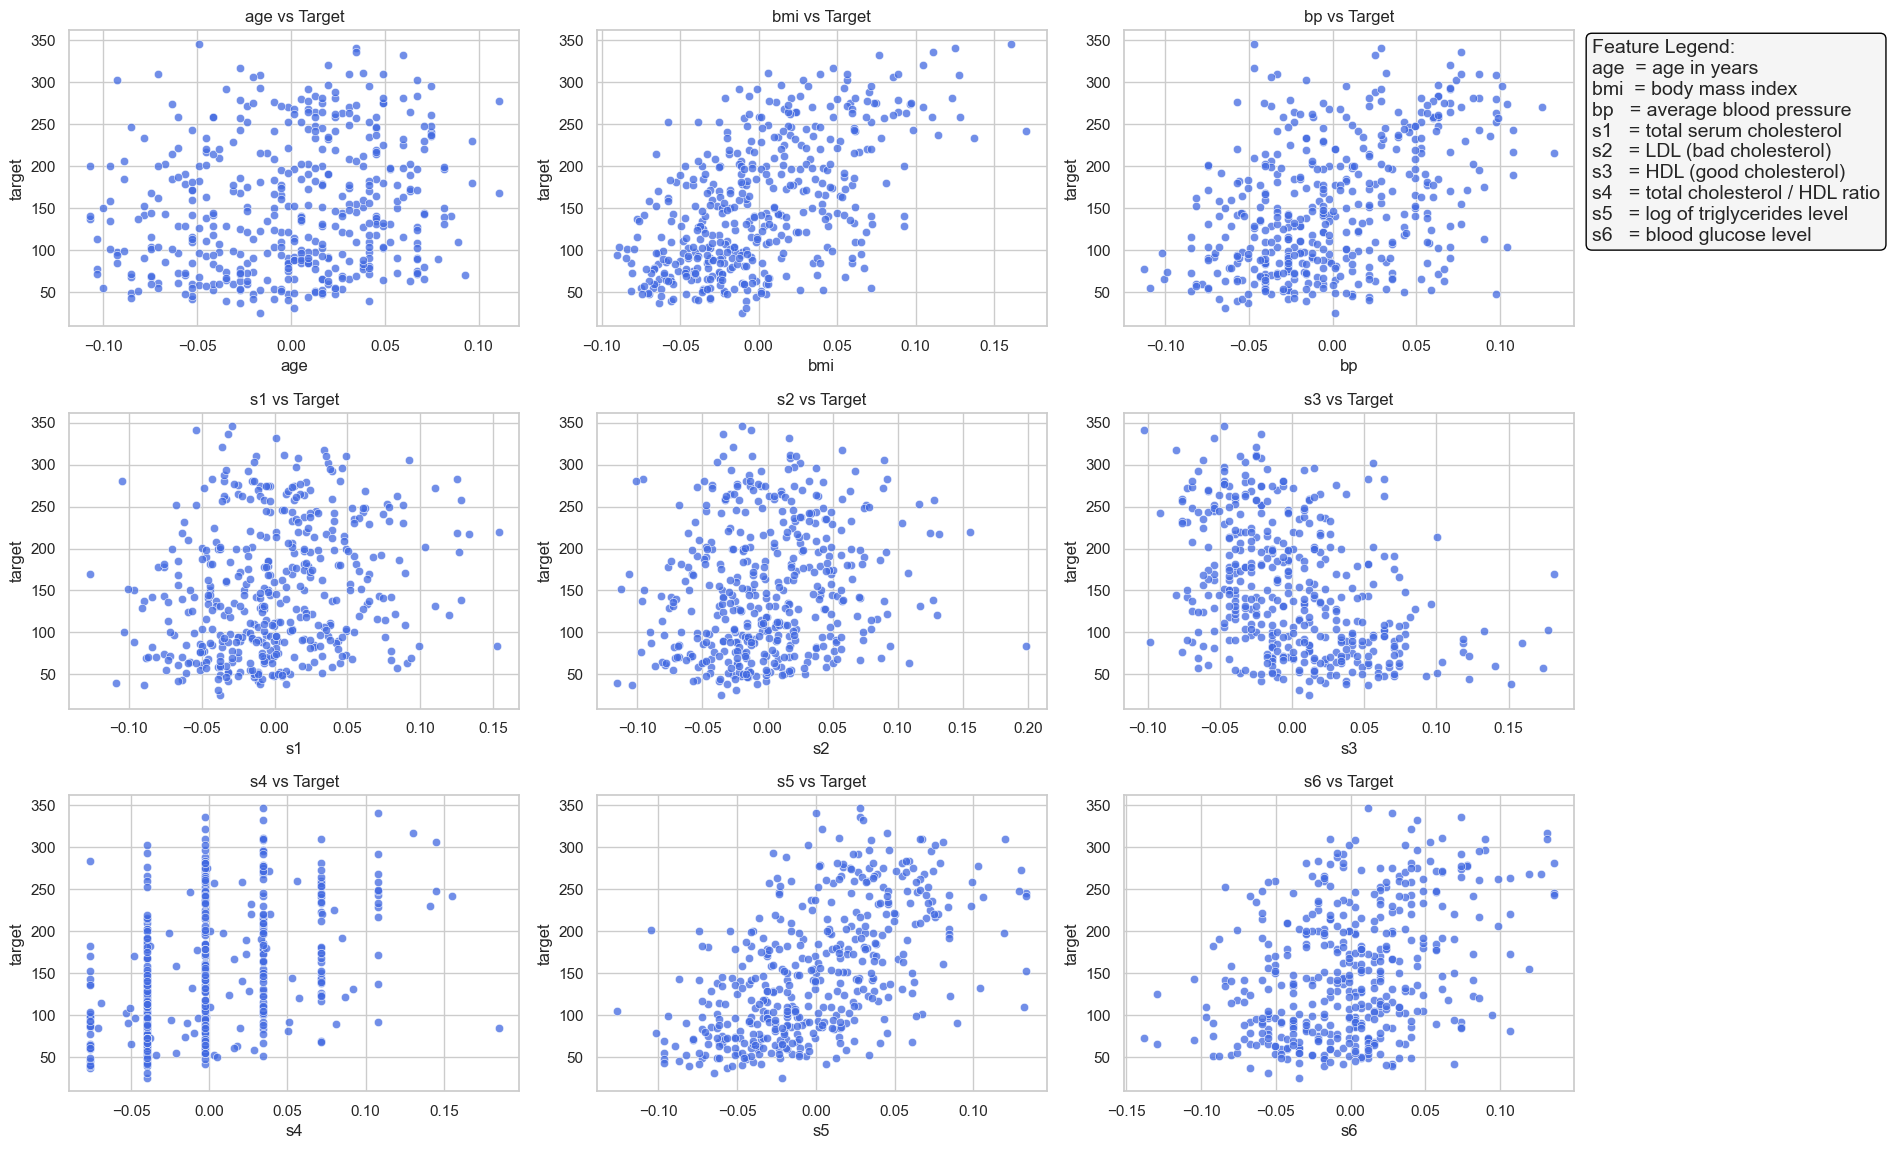

In [8]:
# display the relationship and correlation between the target and other features
features = [f for f in diabetes.feature_names if f != "sex"]  # exclude "sex"

plt.figure(figsize=(20,15))

for i, feat in enumerate(features):
    plt.subplot(4, 3, i+1)
    sns.scatterplot(x=df[feat], y=df["target"], alpha=0.75, color="royalblue")
    plt.title(f"{feat} vs Target")

# --- Add feature legend ---
legend_text = (
    "Feature Legend:\n"
    "age  = age in years\n"
    "bmi  = body mass index\n"
    "bp   = average blood pressure\n"
    "s1   = total serum cholesterol\n"
    "s2   = LDL (bad cholesterol)\n"
    "s3   = HDL (good cholesterol)\n"
    "s4   = total cholesterol / HDL ratio\n"
    "s5   = log of triglycerides level\n"
    "s6   = blood glucose level"
)

plt.gcf().text(
    0.8, 0.9, legend_text,
    fontsize=14,
    va='center',
    bbox=dict(boxstyle="round", fc="whitesmoke", ec="black")
)

plt.tight_layout(rect=[0, 0, 0.8, 1])  # leave room on right for legend
plt.show()

## Below we took the random regressor and prepared it for the HHO optimization by harcoding it into the rf_object function. The HHO class takes that object function as well as lower and upper bounds to optimize and find the best or better hyperparameters. 

In [ ]:
'''
Build an objective function that takes in hyperparameters for a RandomForest model and returns the MSE
The function below unpacks the hyperparameters, builds a RandomForestRegressor model,
Use HHO to optimize the hyperparameters of a RandomForestRegressor on the diabetes dataset and returns the mean squared error on the test set.

params are the parameters the RandomForestRegressor takes in:
- n_estimators: number of trees in the forest
- max_depth: maximum depth of the tree
- min_samples_split: minimum number of samples required to split an internal node
- min_samples_leaf: minimum number of samples required to be at a leaf node
'''

def rf_objective(params):
    # unpack parameters
    n_estimators = int(params[0])
    max_depth = int(params[1])
    min_split = int(params[2])
    min_leaf = int(params[3])

    # build model
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=max(min_split, 2),
        min_samples_leaf=max(min_leaf, 1),
        random_state=42
    )

    model.fit(diabetesX_train, diabetesY_train)
    preds = model.predict(diabetesX_test)

    mse = mean_squared_error(diabetesY_test, preds)
    return mse

#createe the lower and upper bounds for each hyperparameter
lower_bounds = [50,  2,  2, 1]
upper_bounds = [300, 20, 20, 10]

#run HHO to try tooptimize the RandomForest hyperparameters
hho = HHO(
    obj_func=rf_objective,
    population_size=25,
    dimensions=4,
    lower_bound=lower_bounds,
    upper_bound=upper_bounds,
    T_iter=40
)
best = hho.run()

print("Best position:", best) # printing the best hyperparameters found in the length of the dimensions entered
print("Best value:", rf_objective(best)) # printing the best MSE value found


Best position: [109.20961089  18.23801364  20.           9.96832182]
Best value: 2663.056100080075


## Below we ran multiple parameters using different approachs to test how HHO would perform compared to the baseline models shown below. 
**We ran the array of parameters through the objective funtion to get different results**

In [ ]:
#define some baseline parameter sets for comparison
baseline_param_sets = np.array([
    [100,  0,  2, 1],   # Baseline-ish: 100 trees, no max_depth, default splits/leaves
    [150,  0,  2, 1],   # More trees, still no max_depth
    [150, 10,  2, 1],   # Deeper but bounded trees
    [200, 16,  4, 2],   # More trees, depth similar to your HHO best, mild regularization
    [250,  8, 10, 5],   # Many trees, shallow-ish, stronger regularization
])

for params in baseline_param_sets:
    mse = rf_objective(params)
    print(f"Params: {params}, MSE: {mse}")


Params: [100   0   2   1], MSE: 2952.0105887640448
Params: [150   0   2   1], MSE: 2994.666187765293
Params: [150  10   2   1], MSE: 3032.471226120006
Params: [200  16   4   2], MSE: 2969.407939518787
Params: [250   8  10   5], MSE: 2856.9758292790148


## Once results were obtained we then made the comparison to HHO and plotted the results 

**We saw great immprovents when testing the random forest with harris hawks. For the Mean Square Error testing we saw a decrease at around 10%**

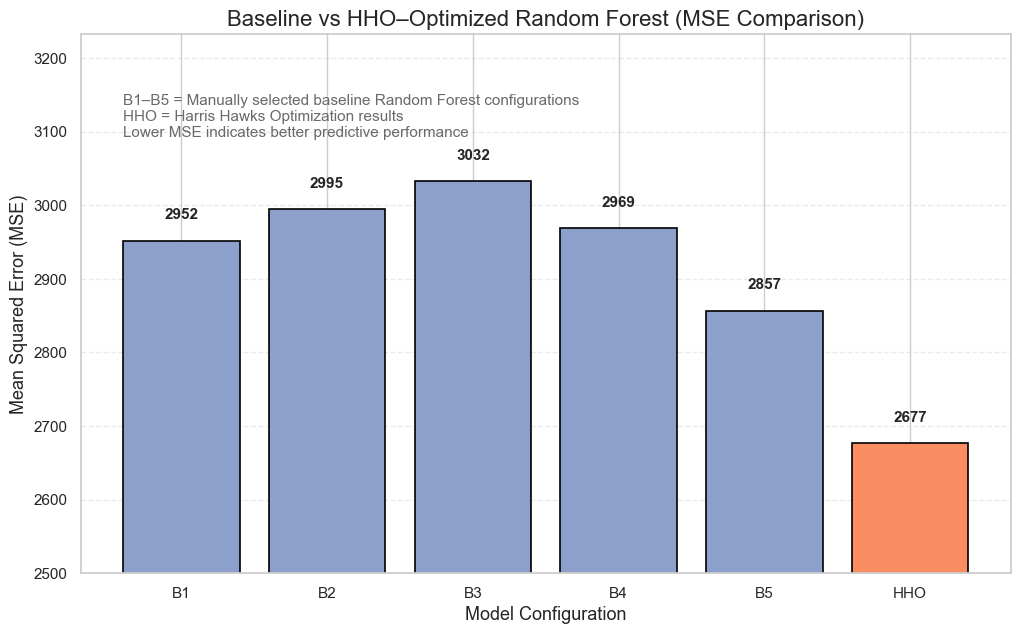

In [ ]:
labels = ["B1", "B2", "B3", "B4", "B5", "HHO"]
mses = [
    2952.0105887640448,
    2994.666187765293,
    3032.471226120006,
    2969.407939518787,
    2856.9758292790148,
    2677.206620681404
]

#color scheme for baseline models and HHO color standout
colors = ["#8da0cb", "#8da0cb", "#8da0cb", "#8da0cb", "#8da0cb", "#fc8d62"]

plt.figure(figsize=(12,7))
bars = plt.bar(labels, mses, color=colors, edgecolor="black", linewidth=1.2)

plt.title("Baseline vs HHO–Optimized Random Forest (MSE Comparison)", fontsize=16)
plt.ylabel("Mean Squared Error (MSE)", fontsize=13)
plt.xlabel("Model Configuration", fontsize=13)

# legend to describe what is the bars mean 
plt.text(
    -0.4, max(mses) * 1.02 ,
    "B1–B5 = Manually selected baseline Random Forest configurations\n"
    "HHO = Harris Hawks Optimization results\n"
    "Lower MSE indicates better predictive performance",
    fontsize=11,
    color="dimgray"
)

# Label bars with exact values
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 25,
        f"{yval:.0f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Scale the y-axis to better fit the MSE values
plt.ylim(2500, max(mses) + 200)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

## Below we show a scatter plot showing preddictions made by the b1 baseline model compared to the HHO optimized model. Plots in the HHO model slight move closer to the red line meaning there was improvent in predicted target values in teh dataset.

Using: n_estimators=100, max_depth=0, min_samples_split=2, min_samples_leaf=1
Baseline MSE: 2952.0105887640448


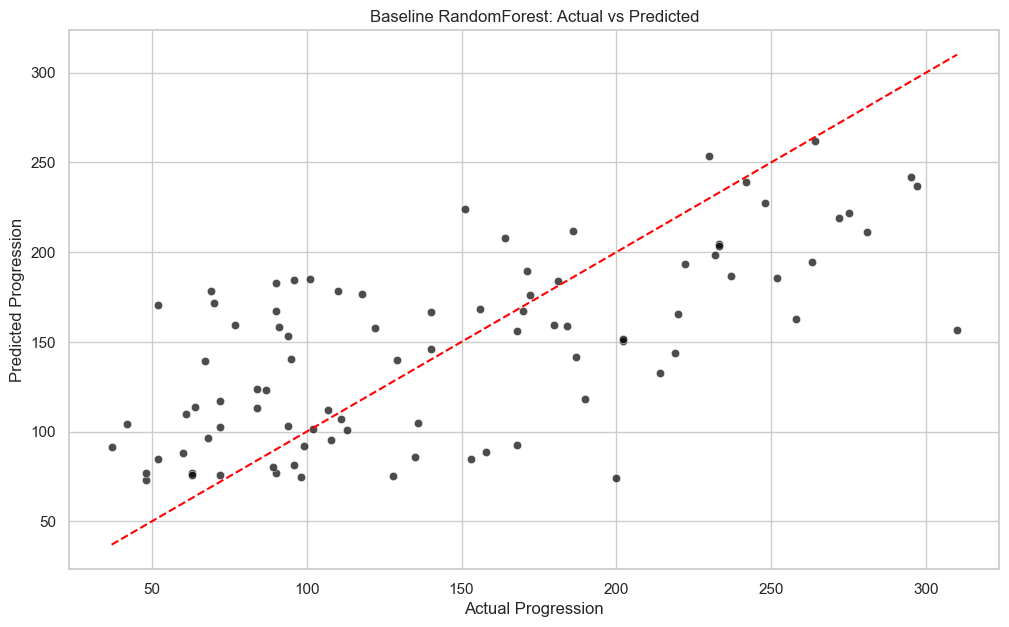

Using: n_estimators=109, max_depth=18, min_samples_split=20, min_samples_leaf=9
Optimized MSE: 2663.056100080075


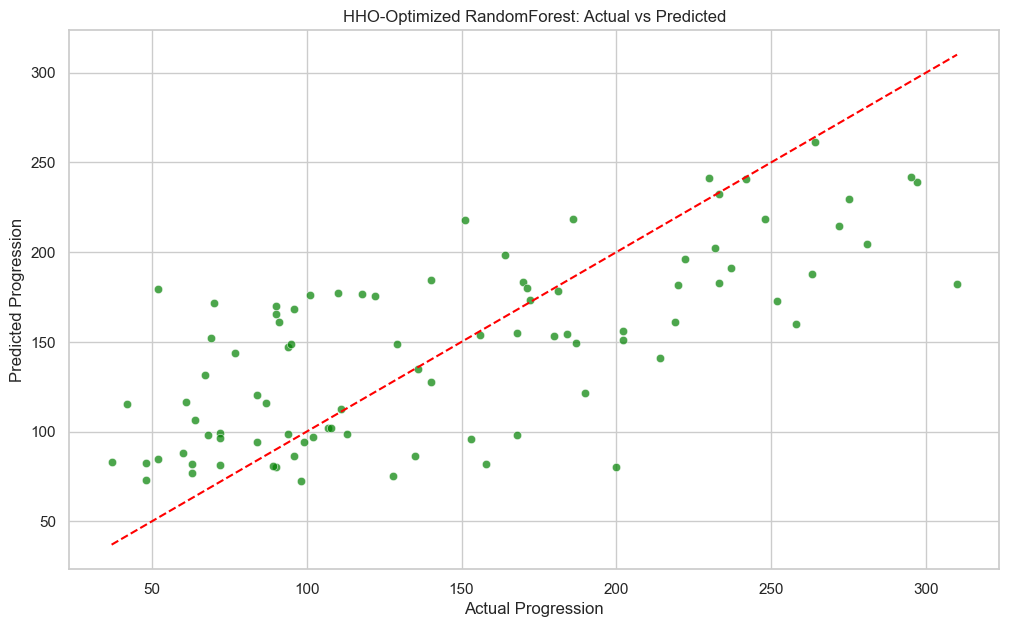

In [40]:
'''
Visualize Predicted vs actual for the baseline model
'''

print(
    f"Using: n_estimators={100}, max_depth={0}, "
    f"min_samples_split={2}, min_samples_leaf={1}"
)
print("Baseline MSE:", baseline_mse)
plt.figure(figsize=(12,7))
sns.scatterplot(x=diabetesY_test, y=pred, alpha=0.7, color='black', legend='full')
plt.plot([diabetesY_test.min(), diabetesY_test.max()],
        [diabetesY_test.min(), diabetesY_test.max()],
        color='red', linestyle='--')  # perfect prediction line

plt.xlabel("Actual Progression")
plt.ylabel("Predicted Progression")
plt.title("Baseline RandomForest: Actual vs Predicted")
plt.show()


best_params = best.astype(int)

n_estimators = best_params[0]
max_depth    = best_params[1]
min_split    = best_params[2]
min_leaf     = best_params[3]

# Enforce valid RandomForest constraints
if max_depth <= 0:
    max_depth = None

min_split = max(min_split, 2)
min_leaf  = max(min_leaf, 1)

print(
    f"Using: n_estimators={n_estimators}, max_depth={max_depth}, "
    f"min_samples_split={min_split}, min_samples_leaf={min_leaf}"
    )


# 2. Build & fit optimized RandomForest
optimized_model = RandomForestRegressor(
    n_estimators=n_estimators,
    max_depth=max_depth,
    min_samples_split=min_split,
    min_samples_leaf=min_leaf,
    random_state=42
)

optimized_model.fit(diabetesX_train, diabetesY_train)
opt_pred = optimized_model.predict(diabetesX_test)

# Compute optimized MSE
opt_mse = mean_squared_error(diabetesY_test, opt_pred)
print("Optimized MSE:", opt_mse)



#Plot Predicted vs Actual for HHO Optimized Model
plt.figure(figsize=(12,7))

sns.scatterplot(
    x=diabetesY_test,
    y=opt_pred,
    alpha=0.7,
    color='green'
)

# Perfect prediction diagonal
plt.plot(
    [diabetesY_test.min(), diabetesY_test.max()],
    [diabetesY_test.min(), diabetesY_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Progression")
plt.ylabel("Predicted Progression")
plt.title("HHO-Optimized RandomForest: Actual vs Predicted")



plt.show()